In [11]:
import sys
from pathlib import Path
import importlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Project Setup
# -----------------------------
project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# -----------------------------
# Import Institutional Backtester
# -----------------------------
import backtester
import importlib
importlib.reload(backtester)

from backtester import VectorizedBacktester

# -----------------------------
# Paths
# -----------------------------
DATA_PROCESSED = project_root / "data_processed"

plt.style.use("bmh")

print("Loading data...")

nifty_long = pd.read_parquet(DATA_PROCESSED / "nifty500_prices.parquet")
sp500_long = pd.read_parquet(DATA_PROCESSED / "sp500_prices.parquet")
nifty_broad = pd.read_parquet(DATA_PROCESSED / "nifty500_2015_prices.parquet")
sp500_broad = pd.read_parquet(DATA_PROCESSED / "sp500_2015_prices.parquet")

# =====================================================
# Select Clustering Algorithm
# =====================================================

ALGORITHM = "agglo"        # Options: "agglo" or "optics"

pair_file = DATA_PROCESSED / f"all_ml_pairs_{ALGORITHM}.csv"

ml_pairs = pd.read_csv(pair_file)

print(f"Running {ALGORITHM.upper()} clustering backtest")

print("Environment Ready.")

Loading data...
Running AGGLO clustering backtest
Environment Ready.


In [12]:
import backtester

print(backtester.__file__)

c:\Users\sanka\OneDrive\Documents\MMU\ML STATISTICAL ARBITRAGE\notebooks\backtester.py


In [13]:
import matplotlib.pyplot as plt

def run_cohort_backtest(market_name, cohort_name, prices_df, all_pairs_df):

    m_key = "NIFTY" if "NIFTY" in market_name.upper() else "SPX"
    print(f"\n{'='*60}\nRUNNING: {market_name} ({cohort_name})\n{'='*60}")

    cohort_pairs = all_pairs_df[
        (all_pairs_df['Market'] == market_name) & 
        (all_pairs_df['Cohort'] == cohort_name)
    ]

    bt = VectorizedBacktester(prices_df, market=m_key, entry_z=2.0, stop_loss=-0.05)


    # Backtest every validated ML pair directly
    all_results = []

    printed = False

    for _, pair in cohort_pairs.iterrows():

        result = bt.run_pair_backtest(
            pair["Ticker1"],
            pair["Ticker2"]
        )

        if result:

            if not printed:
                print("Result keys:", result.keys())
                printed = True

            all_results.append(result)
       
            
    if len(all_results) == 0:
        print("No valid backtest results.")
        return None

    # ==========================================================
    # Build Results DataFrame
    # ==========================================================

    results_df = (
        pd.DataFrame(all_results)
        .sort_values("Sharpe", ascending=False)
        .reset_index(drop=True)
    )

    # Add compatibility column
    results_df = (
        pd.DataFrame(all_results)
        .sort_values("Sharpe", ascending=False)
        .reset_index(drop=True)
    )

    results_df["Total_Return"] = results_df["ROI"] * 100
    results_df["Rank"] = np.arange(1, len(results_df) + 1)

    # ==========================================================
    # Institutional Summary
    # ==========================================================

    print("\n")
    print("="*80)
    print(f"{market_name} ({cohort_name.upper()})")
    print("="*80)
    print(results_df.columns.tolist())
    print(results_df.head())
    print(results_df.head())

    summary = pd.DataFrame({

        "Metric":[
            "Pairs Backtested",
            "Average Sharpe",
            "Median Sharpe",
            "Best Sharpe",
            "Average CAGR (%)",
            "Average Return (%)",
            "Average Drawdown (%)",
            "Winning Pairs (%)"
        ],

        "Value":[

            len(results_df),

            results_df["Sharpe"].mean(),

            results_df["Sharpe"].median(),

            results_df["Sharpe"].max(),

            results_df["CAGR"].mean(),

            results_df["Total_Return"].mean(),

            results_df["Max_Drawdown"].mean(),

            (results_df["Total_Return"]>0).mean()*100
        ]
    })

    print(summary)

    # ==========================================================
    # Top 10 Pairs
    # ==========================================================

    print("\nTOP 10 PAIRS\n")

    print(

    results_df[
    [
    "Rank",
    "ticker1",
    "ticker2",
    "Sharpe",
    "CAGR",
    "Total_Return",
    "Max_Drawdown"
    ]
    ].head(10)

    )

    best = results_df.iloc[0]
    equity = best["equity_curve"]
    # ==========================================================
    # Portfolio Backtest
    # ==========================================================

    portfolio = bt.portfolio_backtest(
        cohort_pairs,
        weighting="equal"
    )

    if portfolio:

        print("\n")
        print("="*80)
        print("PORTFOLIO PERFORMANCE")
        print("="*80)

        print(f"Portfolio Sharpe      : {portfolio['Sharpe']:.2f}")
        print(f"Portfolio CAGR        : {portfolio['CAGR']:.2f}%")
        print(f"Portfolio Return      : {portfolio['ROI']*100:.2f}%")
        print(f"Portfolio Drawdown    : {portfolio['Max_Drawdown']:.2f}%")
        print(f"Portfolio Sortino     : {portfolio['Sortino']:.2f}")
        print(f"Portfolio Calmar      : {portfolio['Calmar']:.2f}")
        print(f"Portfolio Trade Count : {portfolio['Trade_Count']}")

    print(f"Final Equity: {equity.iloc[-1]:.4f}")
    print(f"Max Drawdown: {best['Max_Drawdown']:.2f}%")

    # ==========================
    # PROFESSIONAL EQUITY PLOT
    # ==========================

    plt.style.use("seaborn-v0_8-whitegrid")

    fig, ax = plt.subplots(figsize=(12,6))

    equity.plot(ax=ax, linewidth=2, color="teal",
                label=f"{best['ticker1']} vs {best['ticker2']}")

    # Start marker
    ax.scatter(equity.index[0], equity.iloc[0], 
               color="green", s=80, zorder=5)
    ax.text(equity.index[0], equity.iloc[0], "  Start", fontsize=9)

    # End marker
    ax.scatter(equity.index[-1], equity.iloc[-1], 
               color="red", s=80, zorder=5)
    ax.text(equity.index[-1], equity.iloc[-1],
            f"  End: {equity.iloc[-1]:.2f}x",
            fontsize=9)

    ax.set_title(
        f"Equity Curve – Machine Learning Strategy ({market_name} {cohort_name.capitalize()})",
        fontsize=14, weight="bold"
    )

    ax.set_ylabel("Growth of $1 Invested")
    ax.set_xlabel("Date")

    ax.legend()
    plt.tight_layout()
    plt.show()
    # ==========================================================
    # Portfolio Equity Curve
    # ==========================================================

    if portfolio:

        plt.figure(figsize=(12,6))

        portfolio["equity_curve"].plot(
            linewidth=2
        )

        plt.title(
            f"Portfolio Equity Curve ({market_name} {cohort_name})"
        )

        plt.ylabel("Growth of $1")

        plt.grid(True)

        plt.tight_layout()

        plt.show()
        # ==========================================================
        # Sharpe Distribution
        # ==========================================================

        plt.figure(figsize=(8,5))

        results_df["Sharpe"].hist(bins=20)

        plt.title(
            f"Sharpe Ratio Distribution ({market_name} {cohort_name})"
        )

        plt.xlabel("Sharpe")

        plt.ylabel("Frequency")

        plt.tight_layout()

        plt.show()
    
    results_df.to_csv(

    f"{market_name}_{cohort_name}_results.csv".replace(" ","_"),

    index=False

    )

    return results_df

In [14]:
import inspect

print("VectorizedBacktester is loaded from:")
print(inspect.getfile(VectorizedBacktester))

VectorizedBacktester is loaded from:
c:\Users\sanka\OneDrive\Documents\MMU\ML STATISTICAL ARBITRAGE\notebooks\backtester.py



RUNNING: NIFTY 500 (long)
Result keys: dict_keys(['ticker1', 'ticker2', 'Ticker1', 'Ticker2', 'Rolling_Beta', 'ROI', 'CAGR', 'CAGR_Decimal', 'Annual_Return', 'Annual_Return_Decimal', 'Annual_Volatility', 'Annual_Volatility_Decimal', 'Sharpe', 'Sortino', 'Calmar', 'Max_Drawdown', 'Maximum_Drawdown', 'Profit_Factor', 'Win_Rate', 'Average_Trade_Return', 'Average_Holding_Period', 'Trades', 'Trade_Count', 'Turnover', 'trade_log', 'Trade_Log', 'equity_curve', 'returns', 'positions', 'spread', 'z_score'])


NIFTY 500 (LONG)
['ticker1', 'ticker2', 'Ticker1', 'Ticker2', 'Rolling_Beta', 'ROI', 'CAGR', 'CAGR_Decimal', 'Annual_Return', 'Annual_Return_Decimal', 'Annual_Volatility', 'Annual_Volatility_Decimal', 'Sharpe', 'Sortino', 'Calmar', 'Max_Drawdown', 'Maximum_Drawdown', 'Profit_Factor', 'Win_Rate', 'Average_Trade_Return', 'Average_Holding_Period', 'Trades', 'Trade_Count', 'Turnover', 'trade_log', 'Trade_Log', 'equity_curve', 'returns', 'positions', 'spread', 'z_score', 'Total_Return', 'Rank'

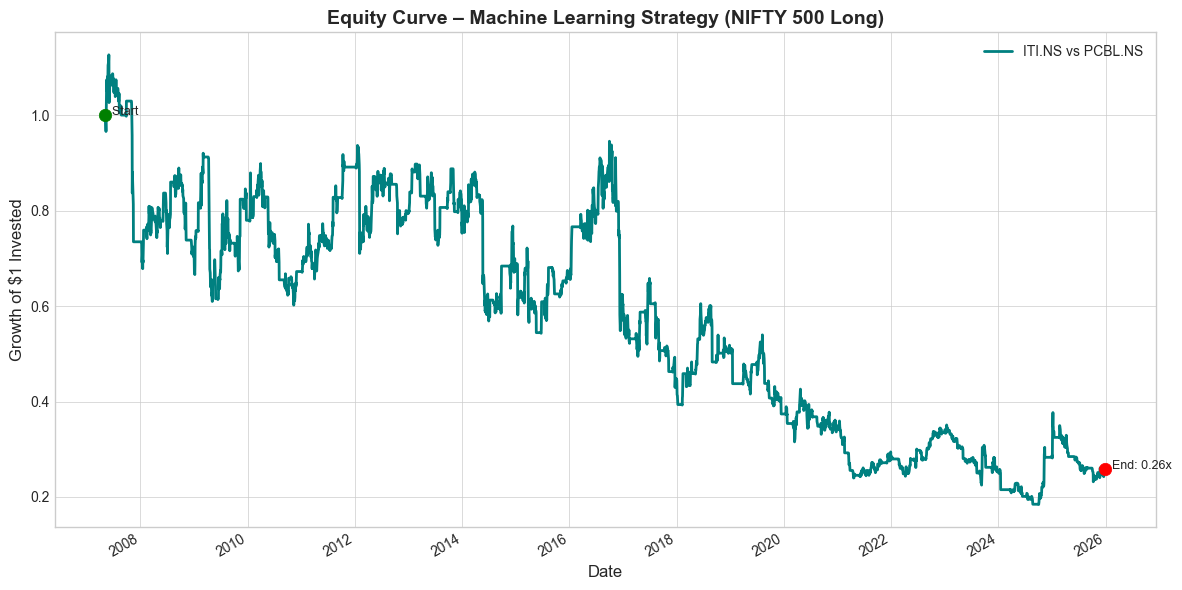

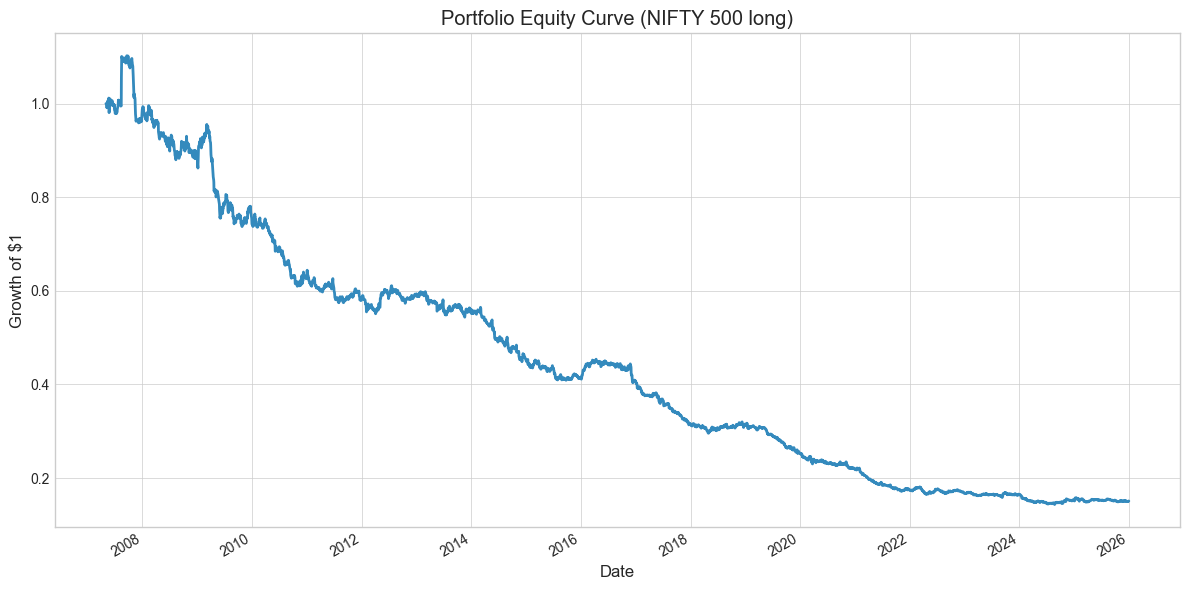

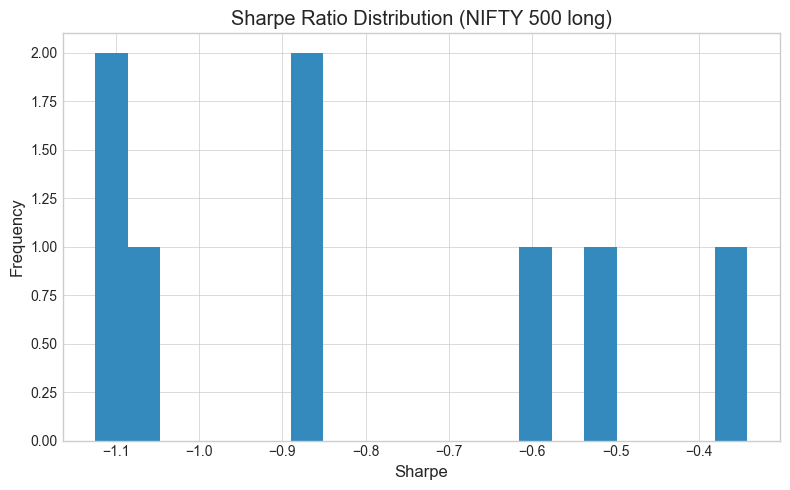


RUNNING: NIFTY 500 (broad)
Result keys: dict_keys(['ticker1', 'ticker2', 'Ticker1', 'Ticker2', 'Rolling_Beta', 'ROI', 'CAGR', 'CAGR_Decimal', 'Annual_Return', 'Annual_Return_Decimal', 'Annual_Volatility', 'Annual_Volatility_Decimal', 'Sharpe', 'Sortino', 'Calmar', 'Max_Drawdown', 'Maximum_Drawdown', 'Profit_Factor', 'Win_Rate', 'Average_Trade_Return', 'Average_Holding_Period', 'Trades', 'Trade_Count', 'Turnover', 'trade_log', 'Trade_Log', 'equity_curve', 'returns', 'positions', 'spread', 'z_score'])


NIFTY 500 (BROAD)
['ticker1', 'ticker2', 'Ticker1', 'Ticker2', 'Rolling_Beta', 'ROI', 'CAGR', 'CAGR_Decimal', 'Annual_Return', 'Annual_Return_Decimal', 'Annual_Volatility', 'Annual_Volatility_Decimal', 'Sharpe', 'Sortino', 'Calmar', 'Max_Drawdown', 'Maximum_Drawdown', 'Profit_Factor', 'Win_Rate', 'Average_Trade_Return', 'Average_Holding_Period', 'Trades', 'Trade_Count', 'Turnover', 'trade_log', 'Trade_Log', 'equity_curve', 'returns', 'positions', 'spread', 'z_score', 'Total_Return', 'Ran

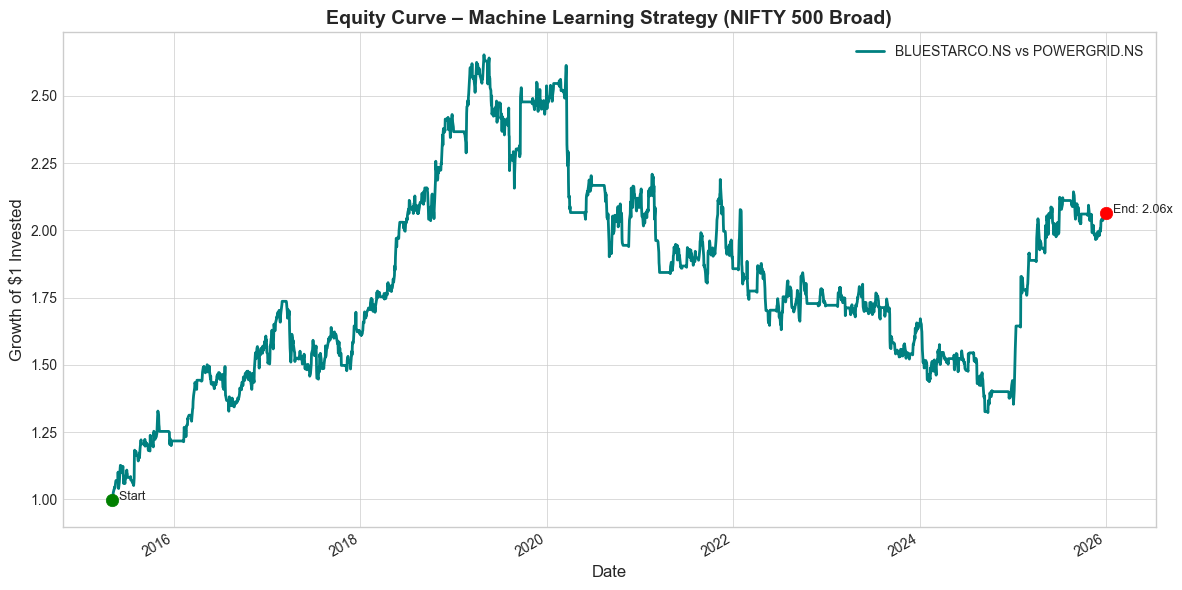

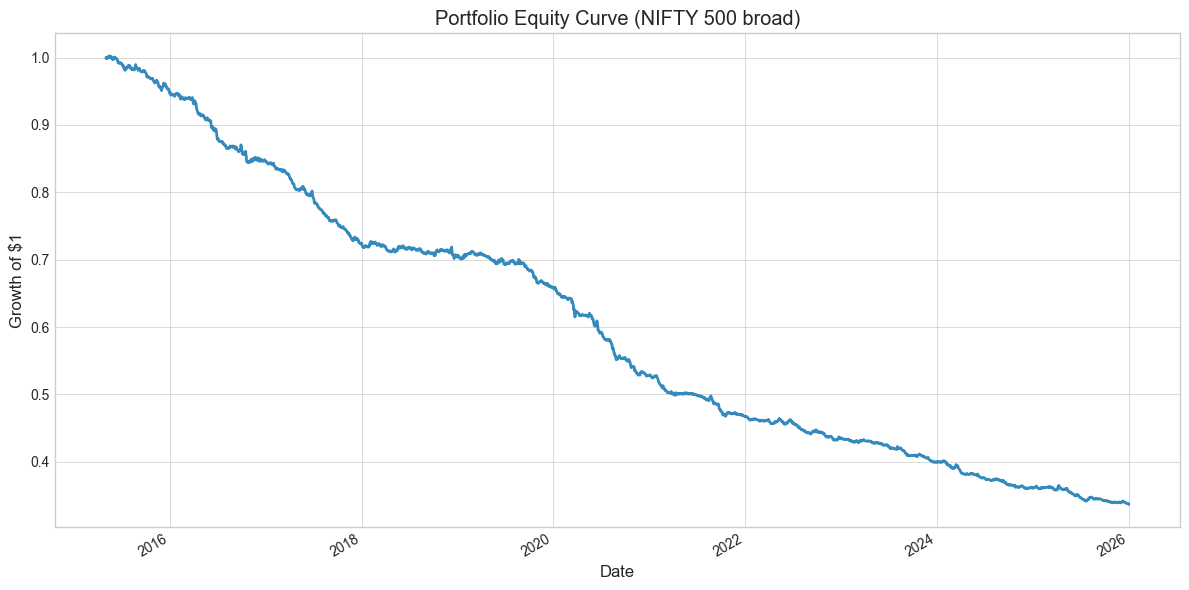

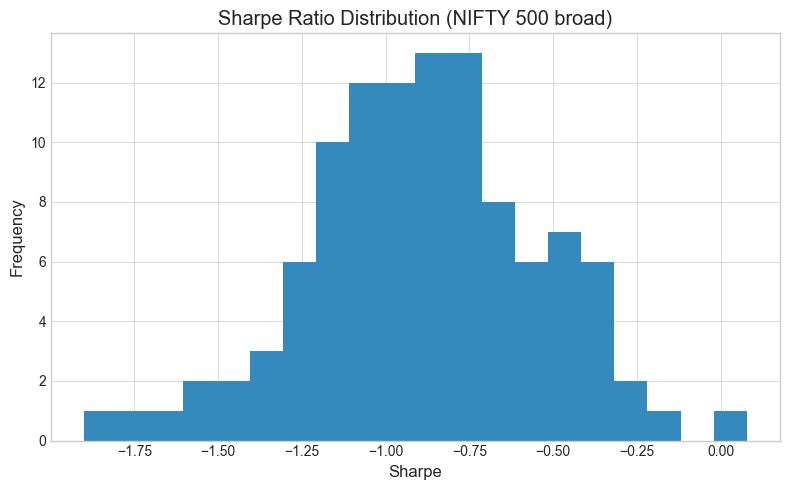


RUNNING: S&P 500 (long)
Result keys: dict_keys(['ticker1', 'ticker2', 'Ticker1', 'Ticker2', 'Rolling_Beta', 'ROI', 'CAGR', 'CAGR_Decimal', 'Annual_Return', 'Annual_Return_Decimal', 'Annual_Volatility', 'Annual_Volatility_Decimal', 'Sharpe', 'Sortino', 'Calmar', 'Max_Drawdown', 'Maximum_Drawdown', 'Profit_Factor', 'Win_Rate', 'Average_Trade_Return', 'Average_Holding_Period', 'Trades', 'Trade_Count', 'Turnover', 'trade_log', 'Trade_Log', 'equity_curve', 'returns', 'positions', 'spread', 'z_score'])


S&P 500 (LONG)
['ticker1', 'ticker2', 'Ticker1', 'Ticker2', 'Rolling_Beta', 'ROI', 'CAGR', 'CAGR_Decimal', 'Annual_Return', 'Annual_Return_Decimal', 'Annual_Volatility', 'Annual_Volatility_Decimal', 'Sharpe', 'Sortino', 'Calmar', 'Max_Drawdown', 'Maximum_Drawdown', 'Profit_Factor', 'Win_Rate', 'Average_Trade_Return', 'Average_Holding_Period', 'Trades', 'Trade_Count', 'Turnover', 'trade_log', 'Trade_Log', 'equity_curve', 'returns', 'positions', 'spread', 'z_score', 'Total_Return', 'Rank']
  

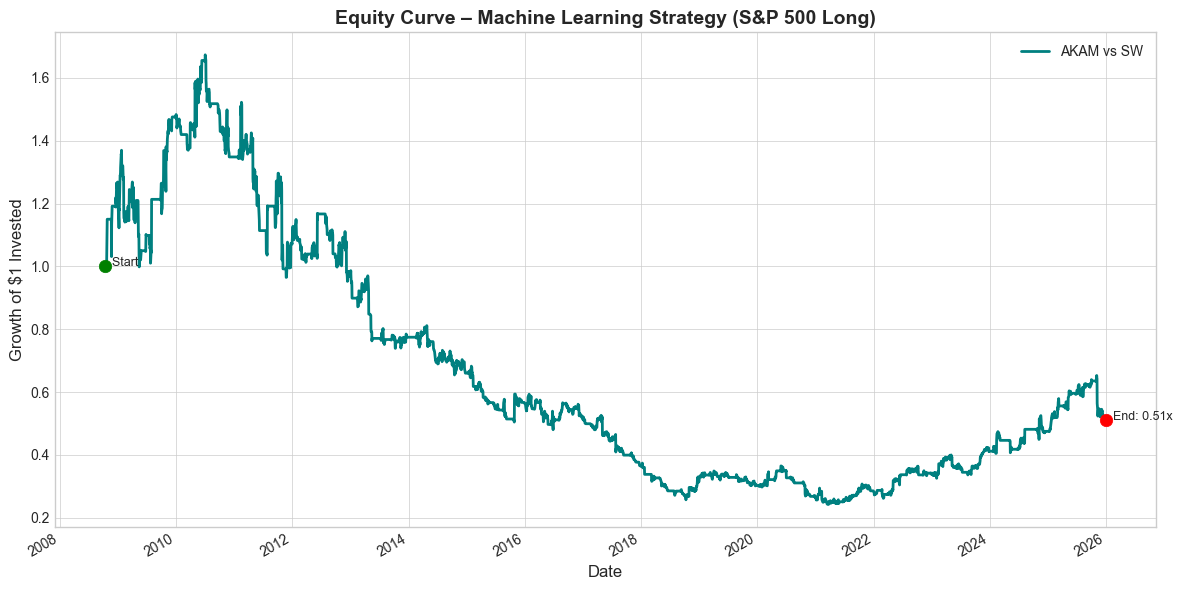

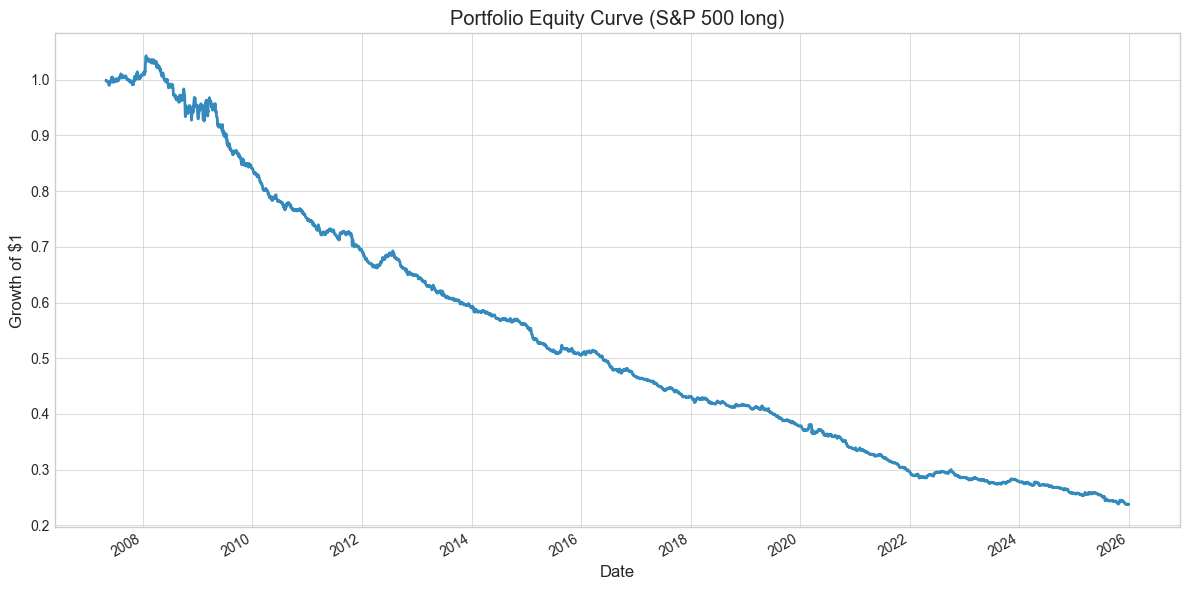

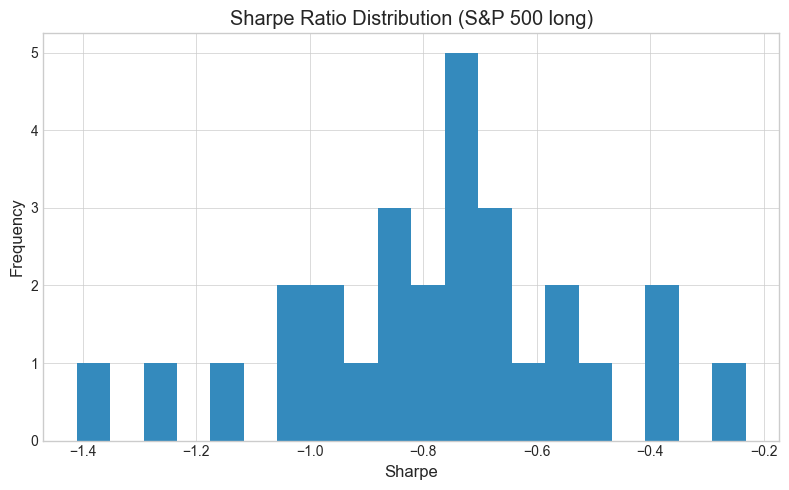


RUNNING: S&P 500 (broad)
Result keys: dict_keys(['ticker1', 'ticker2', 'Ticker1', 'Ticker2', 'Rolling_Beta', 'ROI', 'CAGR', 'CAGR_Decimal', 'Annual_Return', 'Annual_Return_Decimal', 'Annual_Volatility', 'Annual_Volatility_Decimal', 'Sharpe', 'Sortino', 'Calmar', 'Max_Drawdown', 'Maximum_Drawdown', 'Profit_Factor', 'Win_Rate', 'Average_Trade_Return', 'Average_Holding_Period', 'Trades', 'Trade_Count', 'Turnover', 'trade_log', 'Trade_Log', 'equity_curve', 'returns', 'positions', 'spread', 'z_score'])


S&P 500 (BROAD)
['ticker1', 'ticker2', 'Ticker1', 'Ticker2', 'Rolling_Beta', 'ROI', 'CAGR', 'CAGR_Decimal', 'Annual_Return', 'Annual_Return_Decimal', 'Annual_Volatility', 'Annual_Volatility_Decimal', 'Sharpe', 'Sortino', 'Calmar', 'Max_Drawdown', 'Maximum_Drawdown', 'Profit_Factor', 'Win_Rate', 'Average_Trade_Return', 'Average_Holding_Period', 'Trades', 'Trade_Count', 'Turnover', 'trade_log', 'Trade_Log', 'equity_curve', 'returns', 'positions', 'spread', 'z_score', 'Total_Return', 'Rank']


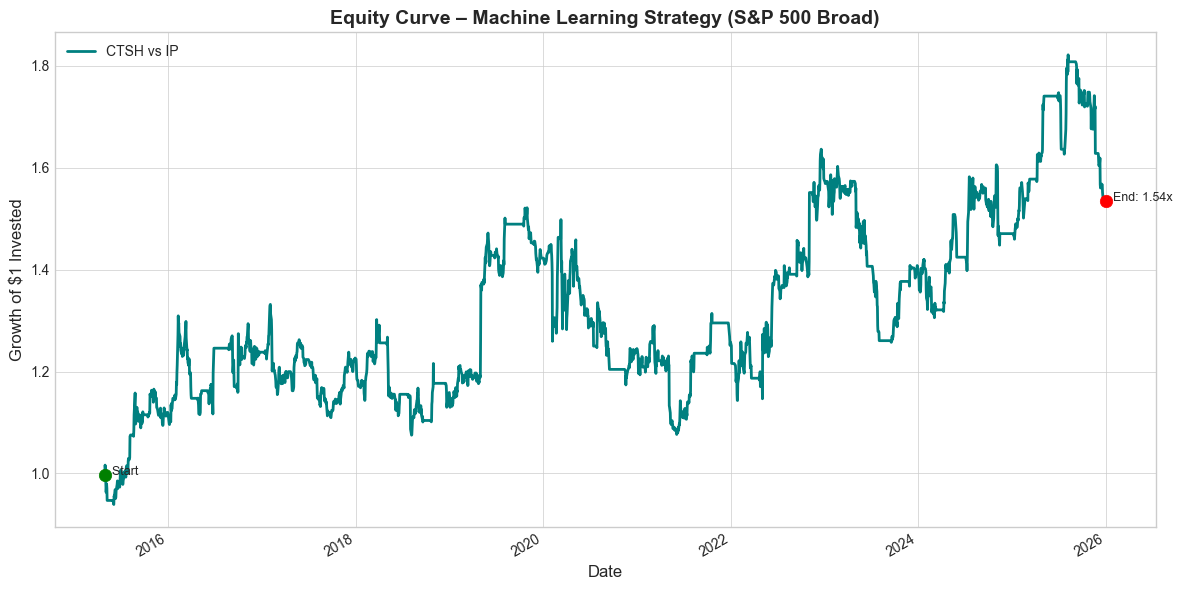

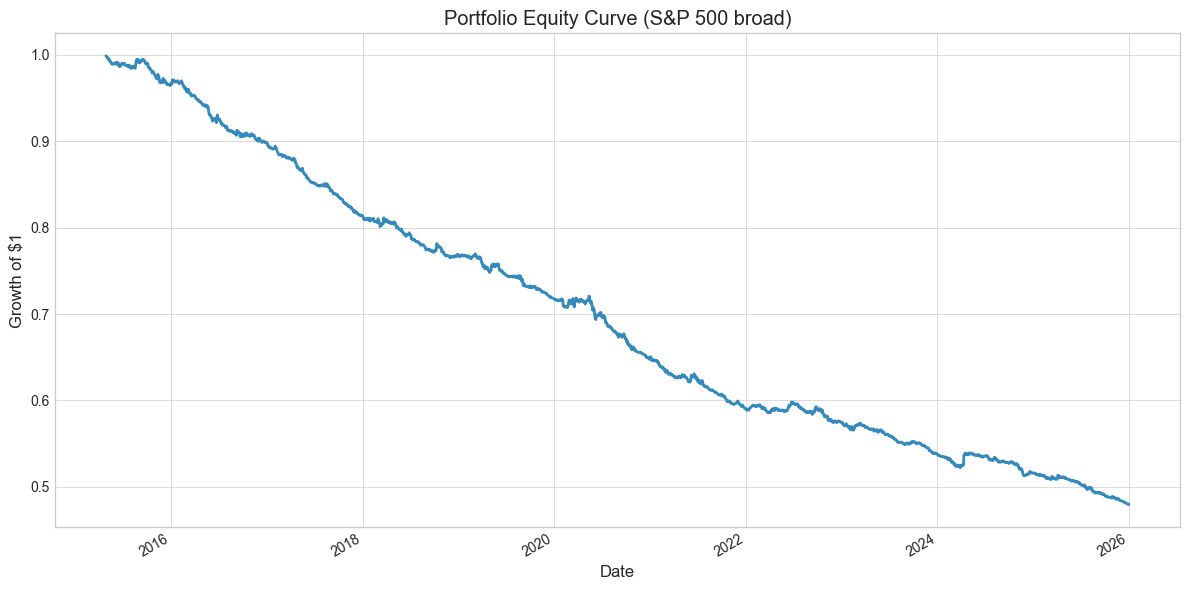

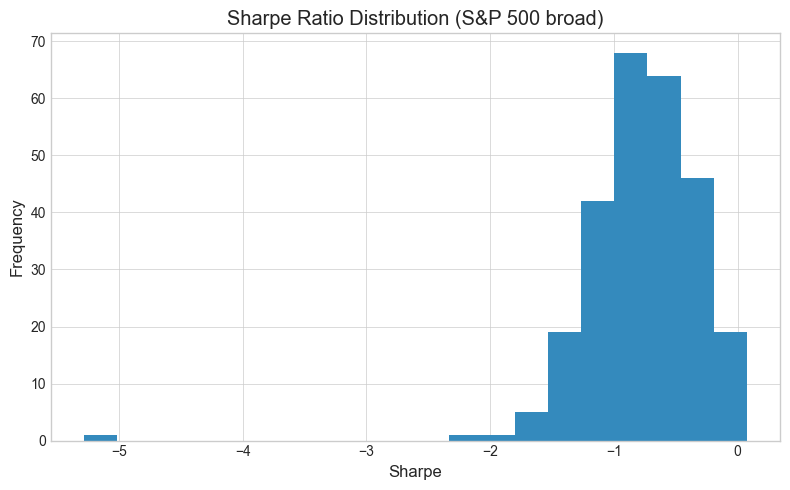

In [15]:
res_n_long = run_cohort_backtest("NIFTY 500", "long", nifty_long, ml_pairs)
res_n_broad = run_cohort_backtest("NIFTY 500", "broad", nifty_broad, ml_pairs)
res_s_long = run_cohort_backtest("S&P 500", "long", sp500_long, ml_pairs)
res_s_broad = run_cohort_backtest("S&P 500", "broad", sp500_broad, ml_pairs)